# EDA Course Project — Phase 1
### Dataset: S&P 500 Constituents (`constituents.csv`)

**Source:** https://raw.githubusercontent.com/salemprakash/EDA/main/Data/constituents.csv

**Tasks covered in this notebook (Phase 1 — 5 marks):**
1. Loading the dataset
2. Basic statistical analysis
3. Handling missing data
4. Data cleaning
5. Data transformation
6. Univariate analysis (≥ 3 visualizations)
7. Bivariate analysis (≥ 3 visualizations)
8. Multivariate analysis (≥ 3 visualizations)

> **Note on this dataset:** `constituents.csv` lists the companies that currently make up
> the S&P 500 index. It is mostly categorical (Symbol, Security name, GICS Sector,
> GICS Sub-Industry, Headquarters Location, Date added, CIK, Founded). To make
> statistical and visual analysis meaningful, we engineer a few numeric features
> from the raw text columns during the *Data Transformation* step (e.g. founding
> year, company age, years since added to the index).


## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
pd.set_option("display.max_columns", None)


## 2. Loading the Dataset

The dataset is read directly from the raw GitHub URL supplied for the project.

In [2]:
DATA_URL = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/constituents.csv"

df = pd.read_csv(DATA_URL)

print("Shape of dataset:", df.shape)
df.head()


Shape of dataset: (503, 8)


,Symbol,Security,GICS Sector,GICS Sub-Industry,Headquarters Location,Date added,CIK,Founded
0,MMM,3M,Industrials,Industrial Conglomerates,"Saint Paul, Minnesota",1957-03-04,66740,1902
1,AOS,A. O. Smith,Industrials,Building Products,"Milwaukee, Wisconsin",2017-07-26,91142,1916
2,ABT,Abbott Laboratories,Health Care,Health Care Equipment,"North Chicago, Illinois",1957-03-04,1800,1888
3,ABBV,AbbVie,Health Care,Biotechnology,"North Chicago, Illinois",2012-12-31,1551152,2013 (1888)
4,ACN,Accenture,Information Technology,IT Consulting & Other Services,"Dublin, Ireland",2011-07-06,1467373,1989


In [3]:
# Column names and data types
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 503 entries, 0 to 502
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   Symbol                 503 non-null    str  
 1   Security               503 non-null    str  
 2   GICS Sector            503 non-null    str  
 3   GICS Sub-Industry      503 non-null    str  
 4   Headquarters Location  503 non-null    str  
 5   Date added             503 non-null    str  
 6   CIK                    503 non-null    int64
 7   Founded                503 non-null    str  
dtypes: int64(1), str(7)
memory usage: 31.6 KB


## 3. Basic Statistical Analysis

Since most columns are categorical (text), we look at:
- Summary statistics for numeric columns (e.g. `CIK`)
- Frequency-based summary statistics for categorical columns
- Cardinality (number of unique values) of each column

In [4]:
# Numeric summary (CIK is the only pure numeric column in the raw data)
df.describe(include=[np.number])


,CIK
count,5.030000e+02
mean,8.217536e+05
std,5.665200e+05
min,1.800000e+03
25%,1.005050e+05
50%,9.000750e+05
75%,1.175188e+06
max,2.005951e+06


In [5]:
# Categorical summary
df.describe(include=[object])


/tmp/ipykernel_345/3634800323.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include=[object])


,Symbol,Security,GICS Sector,GICS Sub-Industry,Headquarters Location,Date added,Founded
count,503,503,503,503,503,503,503
unique,503,503,11,127,252,376,199
top,MMM,3M,Industrials,Health Care Equipment,"New York City, New York",1957-03-04,1993
freq,1,1,78,18,41,54,13


In [6]:
# Number of unique values per column
df.nunique().sort_values(ascending=False)


Symbol                   503
Security                 503
CIK                      500
Date added               376
Headquarters Location    252
Founded                  199
GICS Sub-Industry        127
GICS Sector               11
dtype: int64

In [7]:
# How many companies per GICS Sector
df['GICS Sector'].value_counts()


GICS Sector
Industrials               78
Financials                71
Information Technology    67
Health Care               63
Consumer Discretionary    52
Consumer Staples          38
Utilities                 31
Real Estate               31
Materials                 28
Communication Services    22
Energy                    22
Name: count, dtype: int64

## 4. Handling Missing Data

We check every column for missing (`NaN`) values and decide how to treat them.

In [8]:
missing_counts = df.isnull().sum()
missing_pct = (df.isnull().mean() * 100).round(2)
missing_summary = pd.DataFrame({'missing_count': missing_counts, 'missing_%': missing_pct})
missing_summary[missing_summary['missing_count'] > 0].sort_values('missing_count', ascending=False)


,missing_count,missing_%


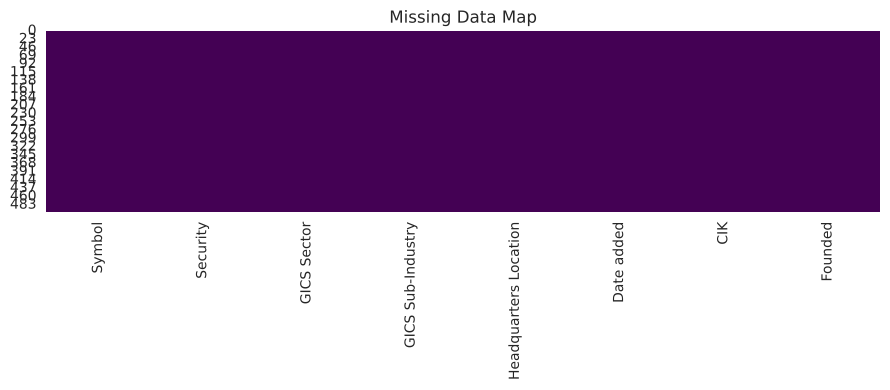

In [9]:
# Visual check for missing data
plt.figure(figsize=(9, 4))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title('Missing Data Map')
plt.tight_layout()
plt.show()


In [10]:
# Strategy:
# - 'Founded' occasionally has multiple/alternate years in parentheses e.g. "2020 (1915, spinoff)"
#   -> treated in Data Cleaning, not a missing-value issue.
# - Any row that is fully duplicated is dropped.
# - Any critical identifier (Symbol, Security) that is missing would be dropped,
#   since there is no way to impute a company's ticker/name.
critical_cols = ['Symbol', 'Security', 'GICS Sector', 'GICS Sub-Industry']
before = len(df)
df = df.dropna(subset=critical_cols)
after = len(df)
print(f"Rows before dropping missing critical fields: {before}")
print(f"Rows after dropping missing critical fields:  {after}")


Rows before dropping missing critical fields: 503
Rows after dropping missing critical fields:  503


## 5. Data Cleaning

Steps performed:
1. Remove exact duplicate rows.
2. Trim whitespace from text columns.
3. Standardise the `Date added` column to a proper `datetime` type.
4. Clean the messy `Founded` column (it sometimes contains text like
   `"2020 (1915, United Technologies spinoff)"`) down to a single usable year.


In [11]:
# 1. Remove duplicates
dup_count = df.duplicated().sum()
print("Exact duplicate rows found:", dup_count)
df = df.drop_duplicates().reset_index(drop=True)


Exact duplicate rows found: 0


In [12]:
# 2. Trim whitespace on all string/object columns
obj_cols = df.select_dtypes(include='object').columns
for c in obj_cols:
    df[c] = df[c].astype(str).str.strip()


/tmp/ipykernel_345/66306500.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  obj_cols = df.select_dtypes(include='object').columns


In [13]:
# 3. Convert 'Date added' to datetime
df['Date added'] = pd.to_datetime(df['Date added'], errors='coerce')
print("Rows where 'Date added' could not be parsed:", df['Date added'].isnull().sum())


Rows where 'Date added' could not be parsed: 0


In [14]:
# 4. Clean the 'Founded' column -> extract the first 4-digit year mentioned
def extract_founded_year(value):
    match = re.search(r'(\d{4})', str(value))
    return int(match.group(1)) if match else np.nan

df['Founded_Year_Clean'] = df['Founded'].apply(extract_founded_year)
df[['Founded', 'Founded_Year_Clean']].head(10)


,Founded,Founded_Year_Clean
0,1902,1902
1,1916,1916
2,1888,1888
3,2013 (1888),2013
4,1989,1989
5,1982,1982
6,1969,1969
7,1981,1981
8,1955,1955
9,1999,1999


In [15]:
# Sanity check: any implausible founding years (e.g. before 1600 or after this year)?
current_year = pd.Timestamp.today().year
implausible = df[(df['Founded_Year_Clean'] < 1600) | (df['Founded_Year_Clean'] > current_year)]
print("Implausible founding years:", len(implausible))
implausible[['Security', 'Founded', 'Founded_Year_Clean']]


Implausible founding years: 0


,Security,Founded,Founded_Year_Clean


In [16]:
# 5. Split 'Headquarters Location' into City and State/Country (best-effort)
loc_split = df['Headquarters Location'].str.rsplit(',', n=1, expand=True)
df['HQ_City'] = loc_split[0].str.strip()
df['HQ_State_Country'] = loc_split[1].str.strip()

df[['Headquarters Location', 'HQ_City', 'HQ_State_Country']].head()


,Headquarters Location,HQ_City,HQ_State_Country
0,"Saint Paul, Minnesota",Saint Paul,Minnesota
1,"Milwaukee, Wisconsin",Milwaukee,Wisconsin
2,"North Chicago, Illinois",North Chicago,Illinois
3,"North Chicago, Illinois",North Chicago,Illinois
4,"Dublin, Ireland",Dublin,Ireland


## 6. Data Transformation

We engineer numeric features from the cleaned data so that statistical and
visual analysis (histograms, correlations, etc.) becomes meaningful:

- **Date_Added_Year** — year the company joined the S&P 500
- **Company_Age** — years since the company was founded
- **Years_In_Index** — years since the company was added to the index


In [17]:
df['Date_Added_Year'] = df['Date added'].dt.year
df['Company_Age'] = current_year - df['Founded_Year_Clean']
df['Years_In_Index'] = current_year - df['Date_Added_Year']

# Bucket companies into founding-era categories for easier grouping later
bins = [0, 1900, 1950, 1980, 2000, 2010, current_year]
labels = ['Pre-1900', '1900-1950', '1951-1980', '1981-2000', '2001-2010', '2011-Present']
df['Founded_Era'] = pd.cut(df['Founded_Year_Clean'], bins=bins, labels=labels)

df[['Security', 'Founded_Year_Clean', 'Company_Age', 'Date_Added_Year', 'Years_In_Index', 'Founded_Era']].head()


,Security,Founded_Year_Clean,Company_Age,Date_Added_Year,Years_In_Index,Founded_Era
0,3M,1902,124,1957,69,1900-1950
1,A. O. Smith,1916,110,2017,9,1900-1950
2,Abbott Laboratories,1888,138,1957,69,Pre-1900
3,AbbVie,2013,13,2012,14,2011-Present
4,Accenture,1989,37,2011,15,1981-2000


In [18]:
# Final cleaned & transformed dataset overview
print("Final shape:", df.shape)
df.dtypes


Final shape: (503, 15)


Symbol                              str
Security                            str
GICS Sector                         str
GICS Sub-Industry                   str
Headquarters Location               str
Date added               datetime64[us]
CIK                               int64
Founded                             str
Founded_Year_Clean                int64
HQ_City                             str
HQ_State_Country                    str
Date_Added_Year                   int32
Company_Age                       int64
Years_In_Index                    int32
Founded_Era                    category
dtype: object

## 7. Univariate Analysis (≥ 3 visualizations)

Examining the distribution of single variables at a time.

/tmp/ipykernel_345/123482491.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='GICS Sector', order=order, palette='viridis')


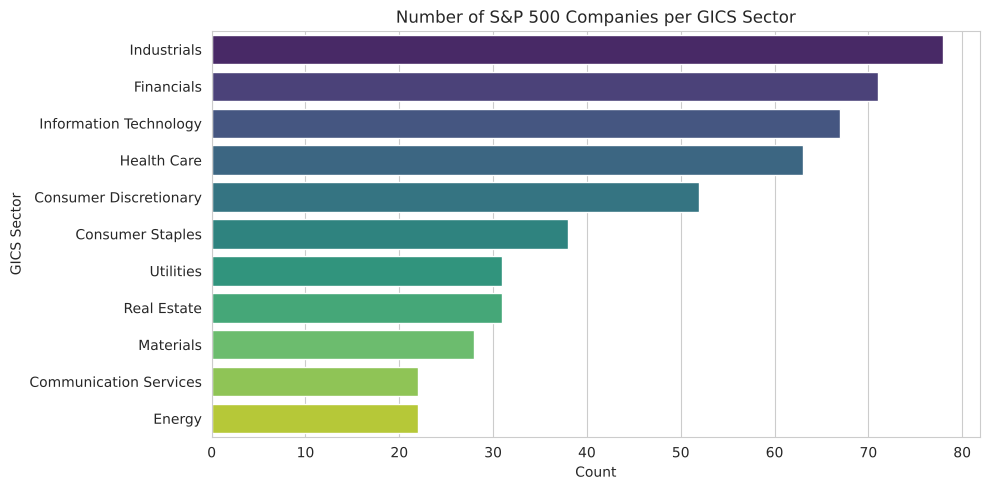

In [19]:
# (1) Number of companies per GICS Sector
plt.figure(figsize=(10, 5))
order = df['GICS Sector'].value_counts().index
sns.countplot(data=df, y='GICS Sector', order=order, palette='viridis')
plt.title('Number of S&P 500 Companies per GICS Sector')
plt.xlabel('Count')
plt.ylabel('GICS Sector')
plt.tight_layout()
plt.show()


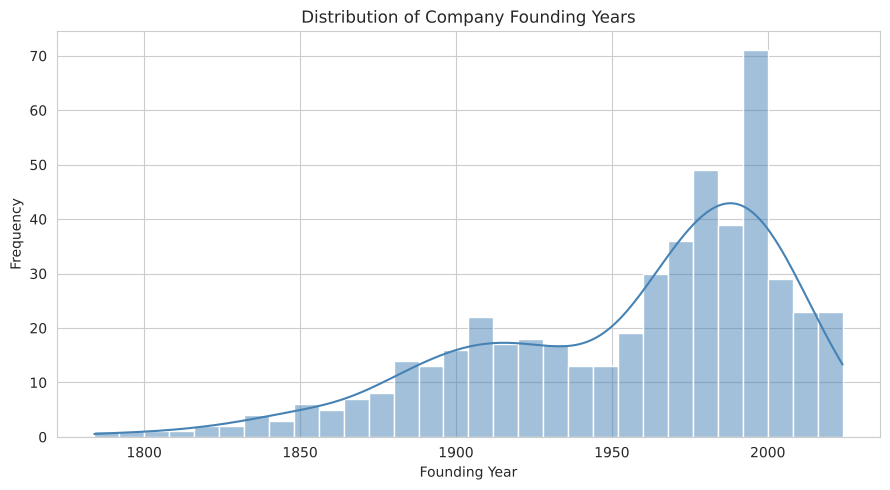

In [20]:
# (2) Distribution of company founding years
plt.figure()
sns.histplot(df['Founded_Year_Clean'].dropna(), bins=30, kde=True, color='steelblue')
plt.title('Distribution of Company Founding Years')
plt.xlabel('Founding Year')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()


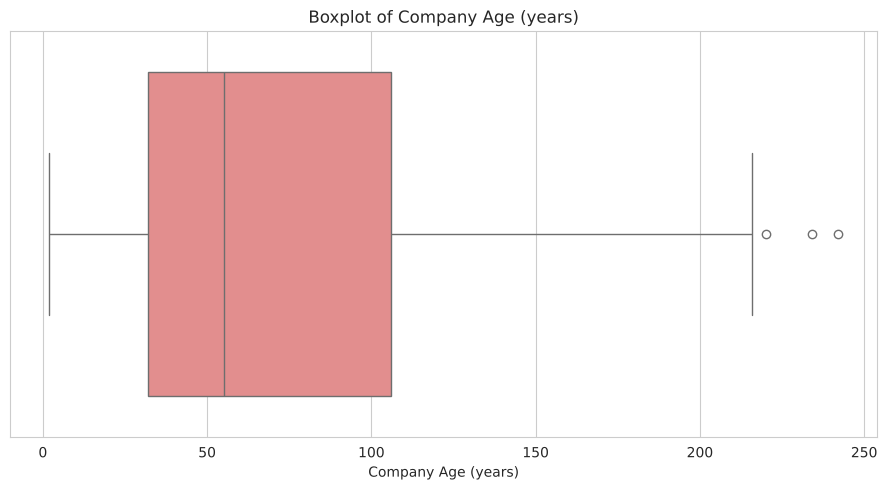

In [21]:
# (3) Distribution of company age (years since founding)
plt.figure()
sns.boxplot(x=df['Company_Age'], color='lightcoral')
plt.title('Boxplot of Company Age (years)')
plt.xlabel('Company Age (years)')
plt.tight_layout()
plt.show()


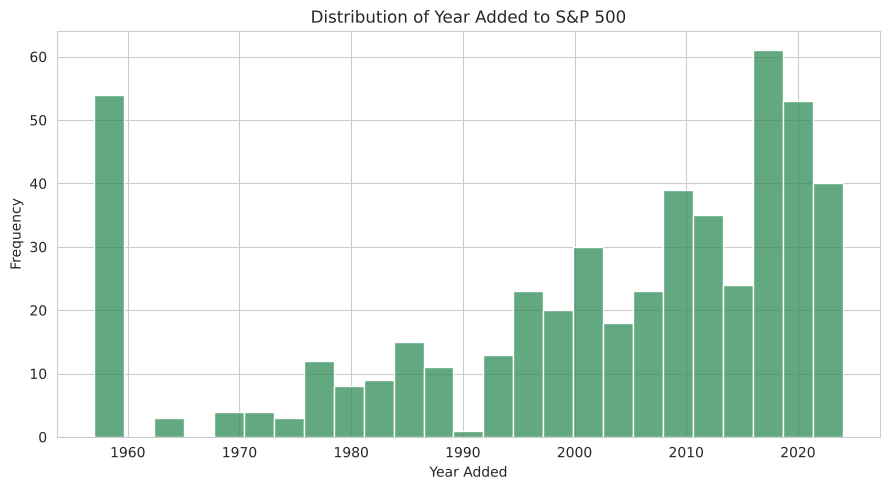

In [22]:
# (4) Distribution of the year companies were added to the S&P 500
plt.figure()
sns.histplot(df['Date_Added_Year'].dropna(), bins=25, color='seagreen')
plt.title('Distribution of Year Added to S&P 500')
plt.xlabel('Year Added')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()


## 8. Bivariate Analysis (≥ 3 visualizations)

Examining the relationship between two variables at a time.

/tmp/ipykernel_345/767783735.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Company_Age', y='GICS Sector', order=order, palette='coolwarm')


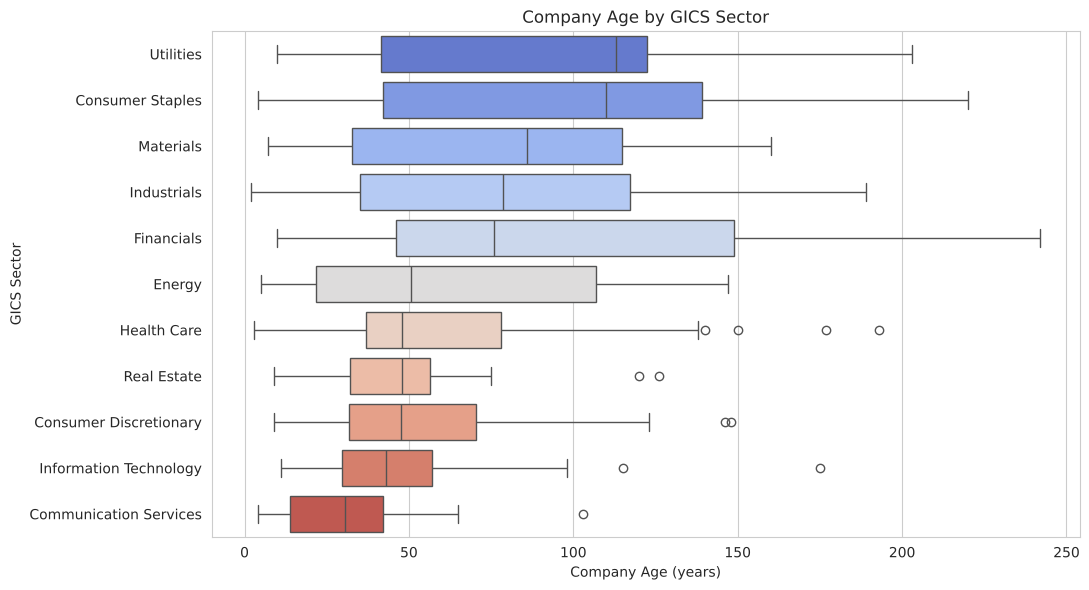

In [23]:
# (1) Company Age vs GICS Sector
plt.figure(figsize=(11, 6))
order = df.groupby('GICS Sector')['Company_Age'].median().sort_values(ascending=False).index
sns.boxplot(data=df, x='Company_Age', y='GICS Sector', order=order, palette='coolwarm')
plt.title('Company Age by GICS Sector')
plt.xlabel('Company Age (years)')
plt.ylabel('GICS Sector')
plt.tight_layout()
plt.show()


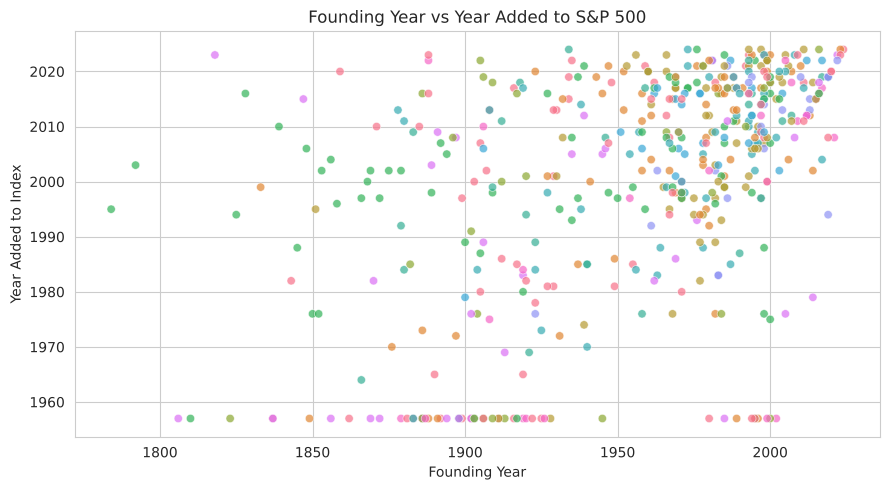

In [24]:
# (2) Founding Year vs Year Added to Index (scatter)
plt.figure()
sns.scatterplot(data=df, x='Founded_Year_Clean', y='Date_Added_Year',
                 hue='GICS Sector', legend=False, alpha=0.7)
plt.title('Founding Year vs Year Added to S&P 500')
plt.xlabel('Founding Year')
plt.ylabel('Year Added to Index')
plt.tight_layout()
plt.show()


/tmp/ipykernel_345/2335210733.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=era_counts.index, y=era_counts.values, palette='mako')


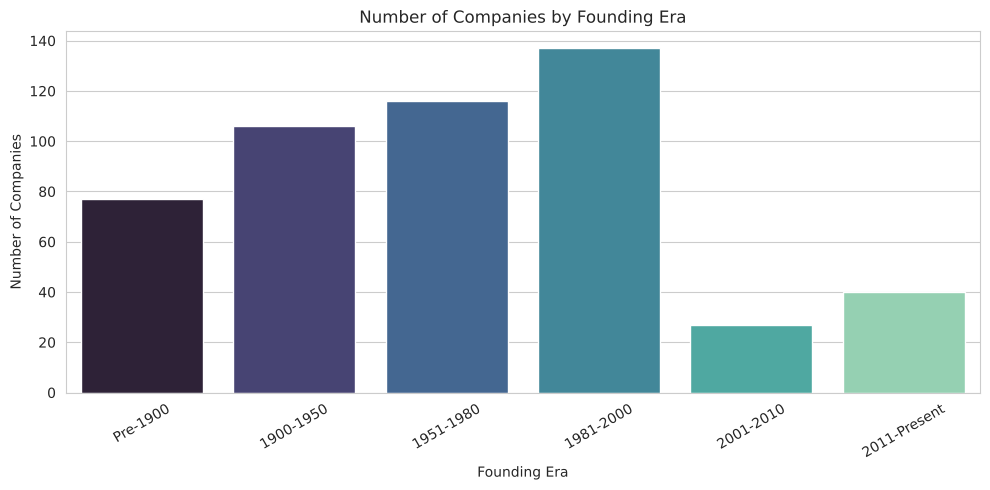

In [25]:
# (3) Number of companies added to the index per decade, by era of founding
plt.figure(figsize=(10, 5))
era_counts = df['Founded_Era'].value_counts().sort_index()
sns.barplot(x=era_counts.index, y=era_counts.values, palette='mako')
plt.title('Number of Companies by Founding Era')
plt.xlabel('Founding Era')
plt.ylabel('Number of Companies')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


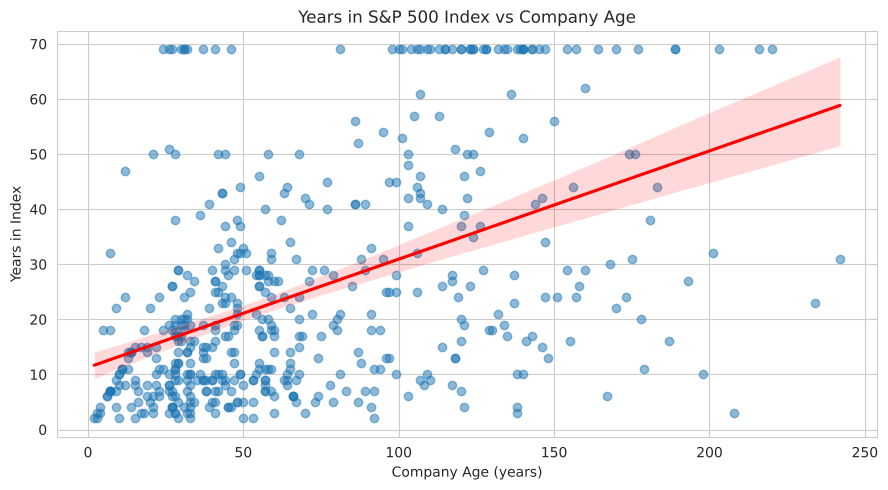

In [26]:
# (4) Years in Index vs Company Age
plt.figure()
sns.regplot(data=df, x='Company_Age', y='Years_In_Index',
            scatter_kws={'alpha': 0.5}, line_kws={'color': 'red'})
plt.title('Years in S&P 500 Index vs Company Age')
plt.xlabel('Company Age (years)')
plt.ylabel('Years in Index')
plt.tight_layout()
plt.show()


## 9. Multivariate Analysis (≥ 3 visualizations)

Examining relationships across three or more variables together.

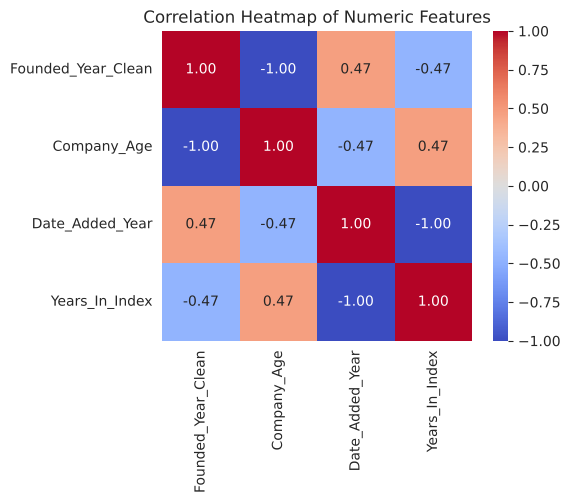

In [27]:
# (1) Correlation heatmap of engineered numeric features
numeric_cols = ['Founded_Year_Clean', 'Company_Age', 'Date_Added_Year', 'Years_In_Index']
corr = df[numeric_cols].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', square=True)
plt.title('Correlation Heatmap of Numeric Features')
plt.tight_layout()
plt.show()


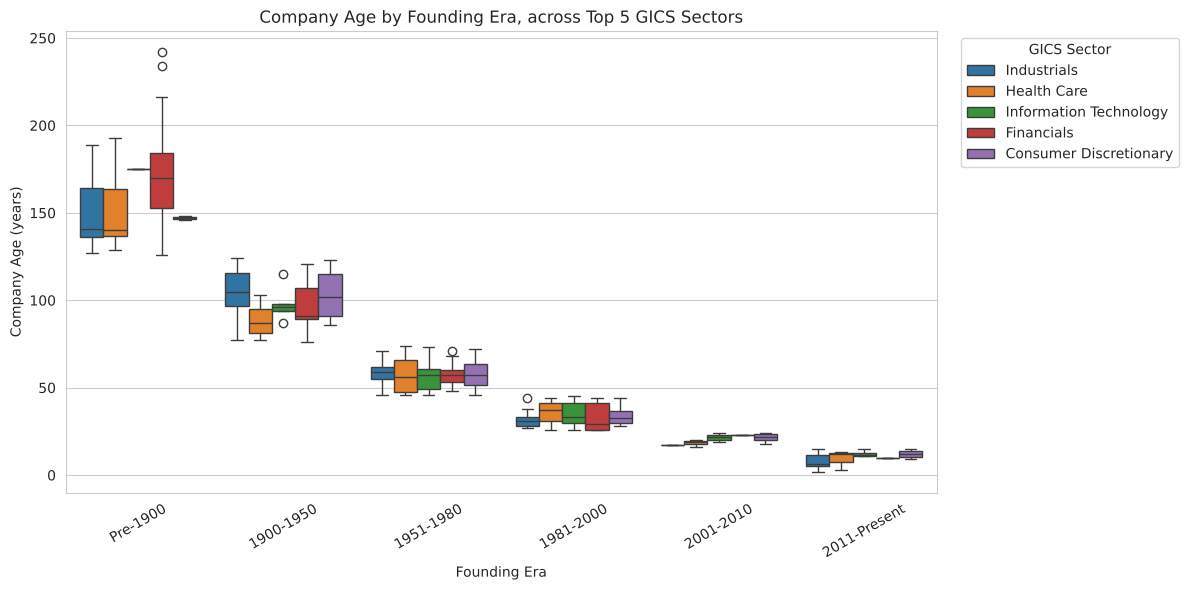

In [28]:
# (2) Company Age across Founding Era, split by top 5 GICS Sectors
top5_sectors = df['GICS Sector'].value_counts().head(5).index
subset = df[df['GICS Sector'].isin(top5_sectors)]

plt.figure(figsize=(12, 6))
sns.boxplot(data=subset, x='Founded_Era', y='Company_Age', hue='GICS Sector')
plt.title('Company Age by Founding Era, across Top 5 GICS Sectors')
plt.xlabel('Founding Era')
plt.ylabel('Company Age (years)')
plt.xticks(rotation=30)
plt.legend(title='GICS Sector', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


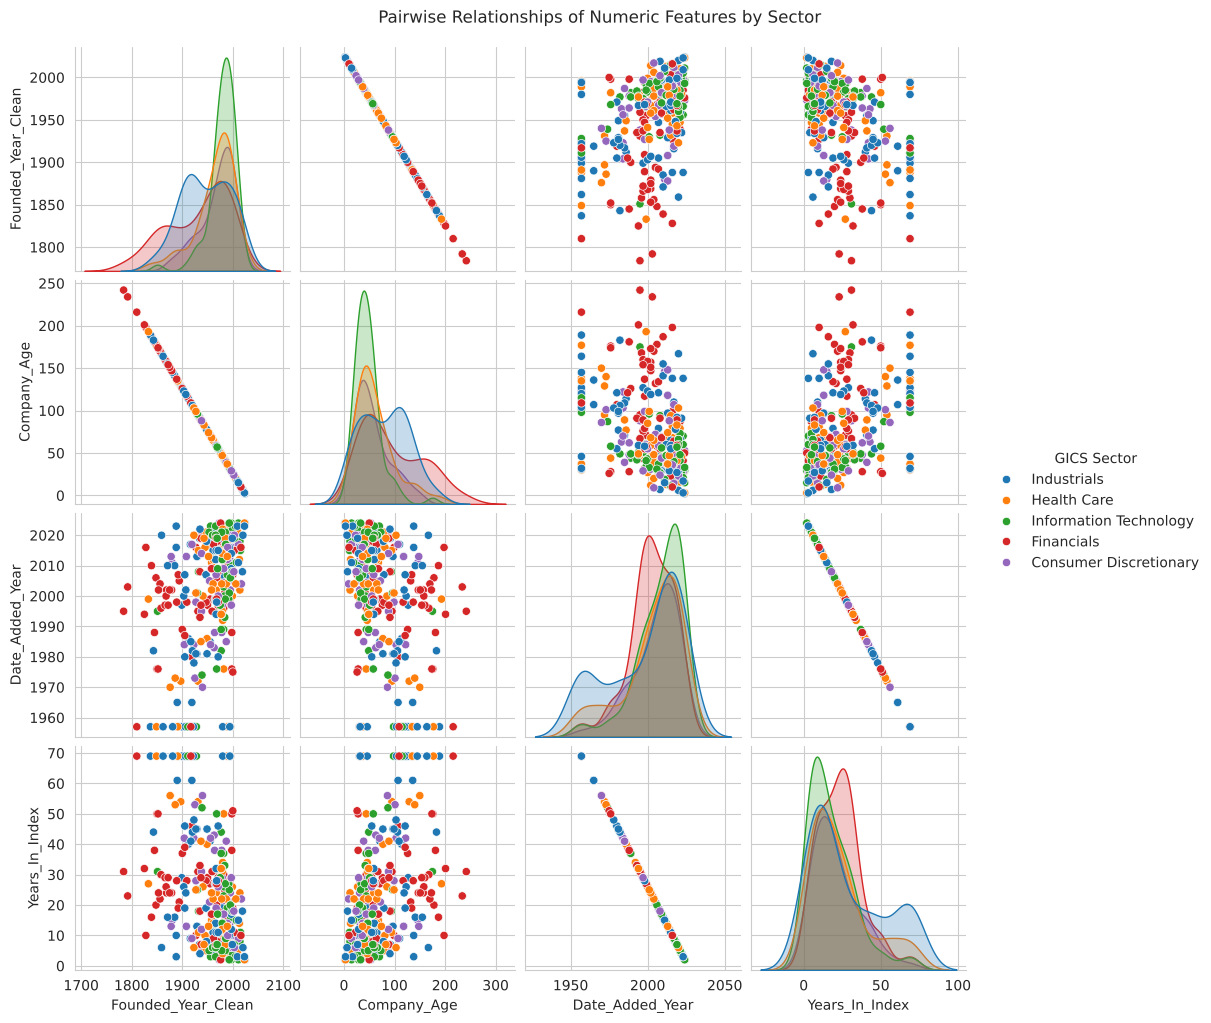

In [29]:
# (3) Pairplot of numeric features, coloured by top 5 GICS Sectors
sns.pairplot(subset[numeric_cols + ['GICS Sector']], hue='GICS Sector', diag_kind='kde')
plt.suptitle('Pairwise Relationships of Numeric Features by Sector', y=1.02)
plt.show()


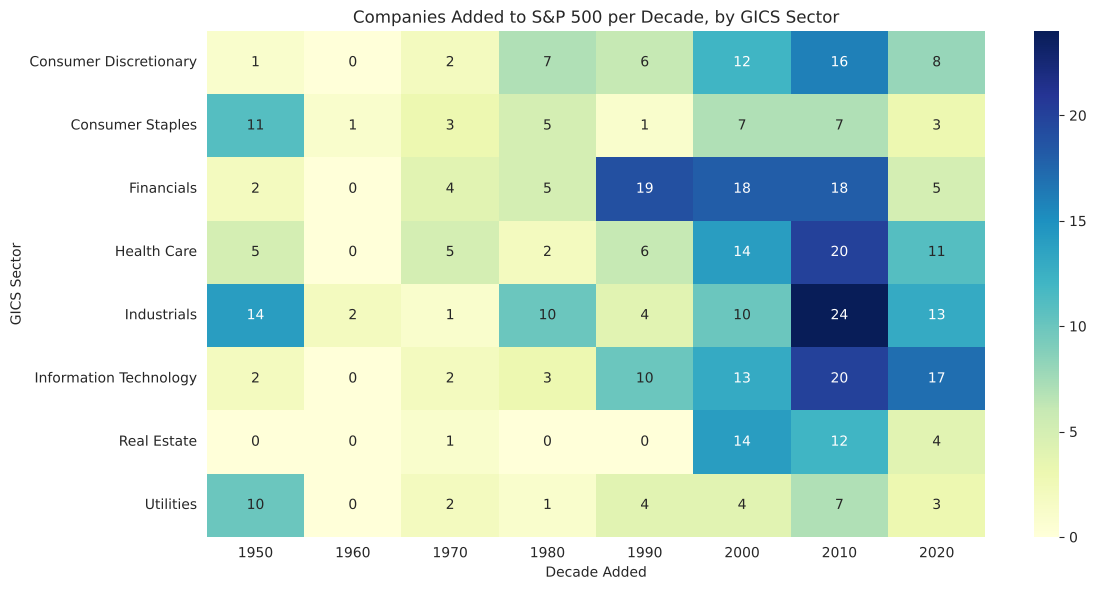

In [30]:
# (4) Heatmap: number of companies added per Year, by GICS Sector (top 8 sectors)
top8_sectors = df['GICS Sector'].value_counts().head(8).index
pivot = (df[df['GICS Sector'].isin(top8_sectors)]
         .assign(Decade=(df['Date_Added_Year'] // 10 * 10))
         .pivot_table(index='GICS Sector', columns='Decade', values='Symbol', aggfunc='count', fill_value=0))

plt.figure(figsize=(12, 6))
sns.heatmap(pivot, annot=True, fmt='d', cmap='YlGnBu')
plt.title('Companies Added to S&P 500 per Decade, by GICS Sector')
plt.xlabel('Decade Added')
plt.ylabel('GICS Sector')
plt.tight_layout()
plt.show()


## 10. Summary of Phase 1

- Dataset loaded directly from the shared GitHub URL.
- Explored structure, data types, and cardinality of every column.
- Checked and handled missing data (dropped rows missing critical identifiers).
- Cleaned duplicate rows, whitespace, dates, and the messy `Founded` text field.
- Engineered new numeric features (`Company_Age`, `Years_In_Index`, `Founded_Era`, HQ split) to enable analysis.
- Produced 4 univariate, 4 bivariate, and 4 multivariate visualizations (each ≥ the required minimum of 3).

**Next (Phase 2 / Phase 3):** deeper statistical testing, feature engineering for modeling, and predictive analysis will build on this cleaned dataset.


---
# PHASE II — 1D, 2D, 3D Statistical Analysis, K-Means and Hierarchical Clustering
(BCSE331L Exploratory Data Analysis — continues in the same notebook, using the cleaned `df` from Phase I)

**Numeric variables used:** `Founded_Year_Clean`, `Date_Added_Year`, `CIK` (SEC registration ID; roughly reflects when a company first registered with the SEC).
`Company_Age` and `Years_In_Index` are just `current_year − Founded` / `current_year − Date_Added_Year`, so they carry no new information and are left out of clustering to avoid double-counting.

In [31]:
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

num = df[['Founded_Year_Clean', 'Date_Added_Year', 'CIK']].dropna().copy()
num['CIK'] = num['CIK'].astype(float)
print(num.shape)
num.head()

(503, 3)


,Founded_Year_Clean,Date_Added_Year,CIK
0,1902,1957,66740.0
1,1916,2017,91142.0
2,1888,1957,1800.0
3,2013,2012,1551152.0
4,1989,2011,1467373.0


## 11. One-Dimensional (1D) Statistical Analysis

In [32]:
rows = []
for col in num.columns:
    s = num[col]
    rows.append({
        'variable': col, 'count': s.count(), 'mean': s.mean(), 'median': s.median(),
        'mode': s.mode().iloc[0], 'std': s.std(), 'variance': s.var(),
        'min': s.min(), 'max': s.max(), 'range': s.max()-s.min(),
        'Q1': s.quantile(.25), 'Q3': s.quantile(.75), 'IQR': s.quantile(.75)-s.quantile(.25),
        'skewness': stats.skew(s), 'kurtosis (excess)': stats.kurtosis(s),
        'CV %': s.std()/s.mean()*100})
desc1d = pd.DataFrame(rows).set_index('variable').T
desc1d.round(3)

variable,Founded_Year_Clean,Date_Added_Year,CIK
count,503.000,503.000,5.030000e+02
mean,1955.738,2000.915,8.217536e+05
median,1971.000,2008.000,9.000750e+05
mode,1998.000,1957.000,1.564708e+06
std,48.749,20.180,5.665200e+05
variance,2376.437,407.214,3.209449e+11
min,1784.000,1957.000,1.800000e+03
max,2024.000,2024.000,2.005951e+06
range,240.000,67.000,2.004151e+06
Q1,1920.000,1992.000,1.005050e+05


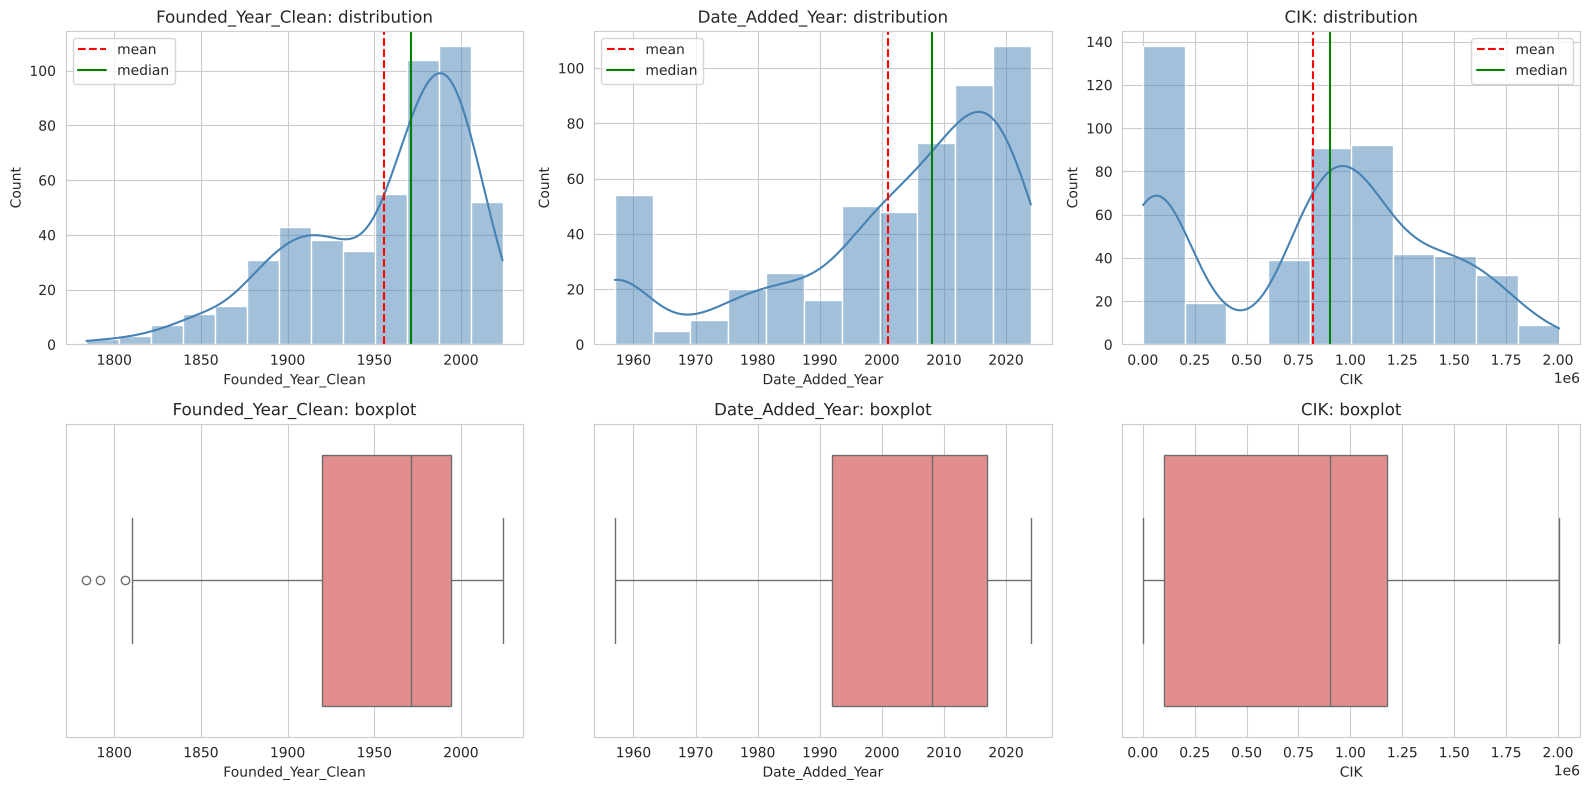

In [33]:
# Histogram + KDE + boxplot for each variable, with mean/median lines
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for i, col in enumerate(num.columns):
    sns.histplot(num[col], kde=True, ax=axes[0, i], color='steelblue')
    axes[0, i].axvline(num[col].mean(), color='red', ls='--', label='mean')
    axes[0, i].axvline(num[col].median(), color='green', ls='-', label='median')
    axes[0, i].set_title(f'{col}: distribution'); axes[0, i].legend()
    sns.boxplot(x=num[col], ax=axes[1, i], color='lightcoral')
    axes[1, i].set_title(f'{col}: boxplot')
plt.tight_layout(); plt.show()

In [34]:
# Outliers (1.5*IQR rule) and normality tests
for col in num.columns:
    s = num[col]; q1, q3 = s.quantile(.25), s.quantile(.75); iqr = q3-q1
    out = ((s < q1-1.5*iqr) | (s > q3+1.5*iqr)).sum()
    sw = stats.shapiro(s); k2 = stats.normaltest(s)
    print(f"{col:20s} outliers={out:3d} | Shapiro p={sw.pvalue:.4g} | D'Agostino p={k2.pvalue:.4g} "
          f"-> {'approx. normal' if sw.pvalue>0.05 else 'NOT normal'}")

Founded_Year_Clean   outliers=  3 | Shapiro p=5.435e-16 | D'Agostino p=1.7e-12 -> NOT normal
Date_Added_Year      outliers=  0 | Shapiro p=4.438e-21 | D'Agostino p=1.13e-14 -> NOT normal
CIK                  outliers=  0 | Shapiro p=5.478e-16 | D'Agostino p=7.886e-40 -> NOT normal


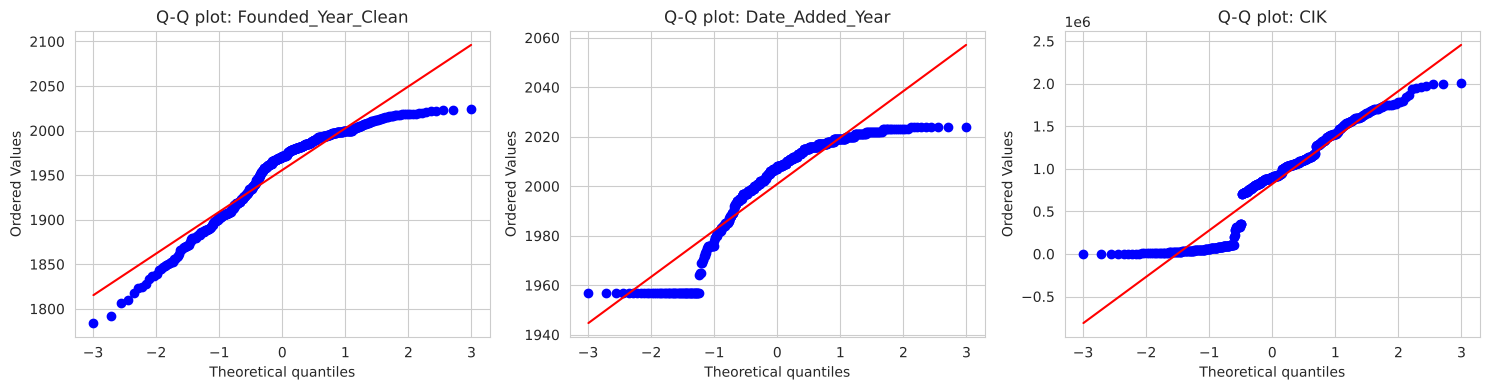

In [35]:
# Q-Q plots
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num.columns):
    stats.probplot(num[col], dist='norm', plot=ax); ax.set_title(f'Q-Q plot: {col}')
plt.tight_layout(); plt.show()

In [36]:
# 1D for the categorical variable: frequency table + Shannon entropy
freq = df['GICS Sector'].value_counts()
pct = (freq/freq.sum()*100).round(2)
print(pd.DataFrame({'count': freq, '%': pct}))
p = freq/freq.sum()
print("\nShannon entropy of sector distribution:", round(-(p*np.log2(p)).sum(), 3), "bits (max =", round(np.log2(len(p)), 3), ")")

                        count      %
GICS Sector                         
Industrials                78  15.51
Financials                 71  14.12
Information Technology     67  13.32
Health Care                63  12.52
Consumer Discretionary     52  10.34
Consumer Staples           38   7.55
Utilities                  31   6.16
Real Estate                31   6.16
Materials                  28   5.57
Communication Services     22   4.37
Energy                     22   4.37

Shannon entropy of sector distribution: 3.321 bits (max = 3.459 )


## 12. Two-Dimensional (2D) Statistical Analysis

Covariance matrix:


,Founded_Year_Clean,Date_Added_Year,CIK
Founded_Year_Clean,2376.44,467.06,1.323429e+07
Date_Added_Year,467.06,407.21,6.307926e+06
CIK,13234290.98,6307925.68,3.209449e+11


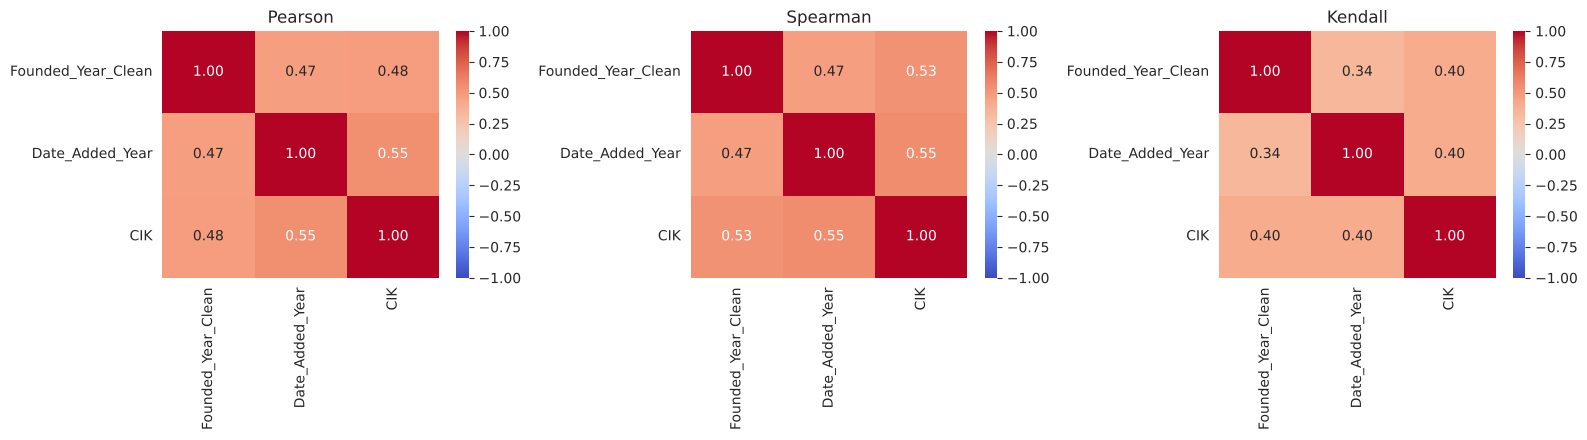

In [37]:
# Covariance and correlation matrices
print("Covariance matrix:"); display(num.cov().round(2))
pear = num.corr(method='pearson'); spear = num.corr(method='spearman'); kend = num.corr(method='kendall')
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, m, t in zip(axes, [pear, spear, kend], ['Pearson', 'Spearman', 'Kendall']):
    sns.heatmap(m, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax); ax.set_title(t)
plt.tight_layout(); plt.show()

In [38]:
# Pairwise correlation tests with p-values
import itertools
res = []
for a, b in itertools.combinations(num.columns, 2):
    r, pr = stats.pearsonr(num[a], num[b]); rho, ps = stats.spearmanr(num[a], num[b])
    res.append({'pair': f'{a} vs {b}', 'pearson r': r, 'p (pearson)': pr, 'spearman rho': rho, 'p (spearman)': ps})
pd.DataFrame(res).round(4)

,pair,pearson r,p (pearson),spearman rho,p (spearman)
0,Founded_Year_Clean vs Date_Added_Year,0.4748,0.0,0.4730,0.0
1,Founded_Year_Clean vs CIK,0.4792,0.0,0.5343,0.0
2,Date_Added_Year vs CIK,0.5518,0.0,0.5549,0.0


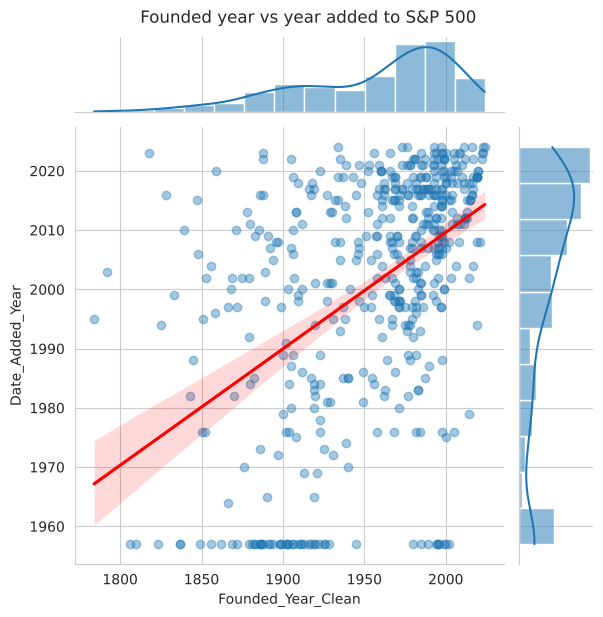

Linear regression: slope=0.1965, R^2=0.2254, p=1.212e-29


In [39]:
# Scatter with regression + marginal distributions
g = sns.jointplot(data=num, x='Founded_Year_Clean', y='Date_Added_Year', kind='reg',
                  joint_kws={'scatter_kws': {'alpha': .4}, 'line_kws': {'color': 'red'}})
g.fig.suptitle('Founded year vs year added to S&P 500', y=1.02); plt.show()
slope, intercept, r, p, se = stats.linregress(num['Founded_Year_Clean'], num['Date_Added_Year'])
print(f"Linear regression: slope={slope:.4f}, R^2={r**2:.4f}, p={p:.4g}")

In [40]:
# Categorical vs numeric: does company age differ by sector? (ANOVA + Kruskal-Wallis)
groups = [g['Founded_Year_Clean'].dropna().values for _, g in df.groupby('GICS Sector') if len(g) > 2]
f, pf = stats.f_oneway(*groups); h, ph = stats.kruskal(*groups)
print(f"One-way ANOVA (founding year by sector): F={f:.3f}, p={pf:.4g}")
print(f"Kruskal-Wallis: H={h:.3f}, p={ph:.4g}")
print("-> sectors", "DO" if ph < 0.05 else "do NOT", "differ significantly in founding year (alpha=0.05)")

One-way ANOVA (founding year by sector): F=9.349, p=2.915e-14
Kruskal-Wallis: H=65.494, p=3.261e-10
-> sectors DO differ significantly in founding year (alpha=0.05)


Chi-square=173.74, dof=50, p=1.418e-15, Cramer's V=0.263


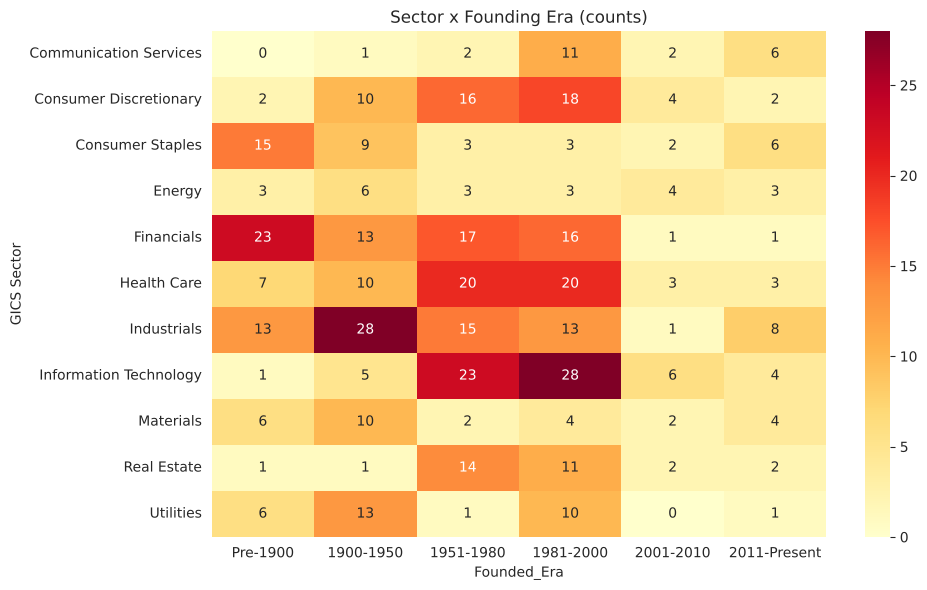

In [41]:
# Categorical vs categorical: Sector vs Founded_Era (chi-square test of independence)
ct = pd.crosstab(df['GICS Sector'], df['Founded_Era'])
chi2, pc, dof, _ = stats.chi2_contingency(ct)
n = ct.values.sum(); cramers_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
print(f"Chi-square={chi2:.2f}, dof={dof}, p={pc:.4g}, Cramer's V={cramers_v:.3f}")
plt.figure(figsize=(10, 6)); sns.heatmap(ct, annot=True, fmt='d', cmap='YlOrRd')
plt.title('Sector x Founding Era (counts)'); plt.tight_layout(); plt.show()

## 13. Three-Dimensional (3D) Statistical Analysis

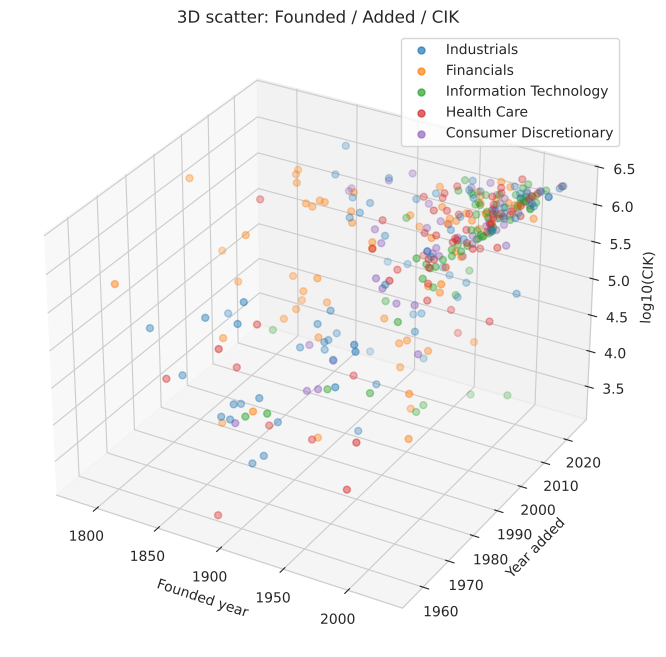

In [42]:
# 3D scatter of the three numeric variables, coloured by sector (top 5 sectors highlighted)
top5 = df['GICS Sector'].value_counts().head(5).index
d3 = df.loc[num.index].copy()
fig = plt.figure(figsize=(11, 8)); ax = fig.add_subplot(111, projection='3d')
for sec in top5:
    m = d3['GICS Sector'] == sec
    ax.scatter(d3.loc[m, 'Founded_Year_Clean'], d3.loc[m, 'Date_Added_Year'],
               np.log10(d3.loc[m, 'CIK'].astype(float)), label=sec, alpha=.7, s=25)
ax.set_xlabel('Founded year'); ax.set_ylabel('Year added'); ax.set_zlabel('log10(CIK)')
ax.set_title('3D scatter: Founded / Added / CIK'); ax.legend(); plt.show()

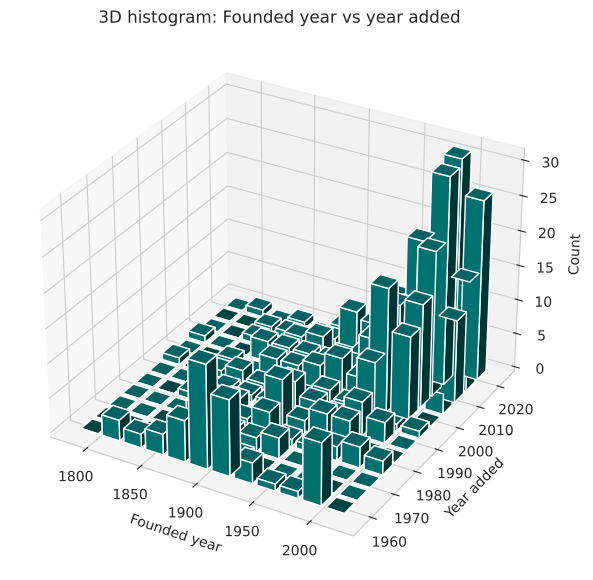

In [43]:
# 3D surface-style view: density of (founded, added) as a 3D histogram
H, xe, ye = np.histogram2d(num['Founded_Year_Clean'], num['Date_Added_Year'], bins=12)
xp, yp = np.meshgrid(xe[:-1], ye[:-1], indexing='ij')
fig = plt.figure(figsize=(10, 7)); ax = fig.add_subplot(111, projection='3d')
ax.bar3d(xp.ravel(), yp.ravel(), 0, (xe[1]-xe[0])*.8, (ye[1]-ye[0])*.8, H.ravel(), shade=True, color='teal')
ax.set_xlabel('Founded year'); ax.set_ylabel('Year added'); ax.set_zlabel('Count')
ax.set_title('3D histogram: Founded year vs year added'); plt.show()

In [44]:
# Multivariate statistics: partial correlation and multiple regression
Z = num.copy(); Z['logCIK'] = np.log10(Z['CIK']); Z = Z.drop(columns='CIK')
# Partial correlation of Founded & Added controlling for logCIK (via residuals)
from numpy.linalg import lstsq
def resid(y, x):
    X = np.c_[np.ones(len(x)), x]; b = lstsq(X, y, rcond=None)[0]; return y - X @ b
pr_, pp_ = stats.pearsonr(resid(Z['Founded_Year_Clean'].values, Z['logCIK'].values),
                          resid(Z['Date_Added_Year'].values, Z['logCIK'].values))
print(f"Partial correlation (Founded, Added | logCIK): r={pr_:.3f}, p={pp_:.4g}")

# Multiple linear regression: Date_Added_Year ~ Founded_Year + logCIK
X = np.c_[np.ones(len(Z)), Z[['Founded_Year_Clean', 'logCIK']].values]; y = Z['Date_Added_Year'].values
b = lstsq(X, y, rcond=None)[0]; yhat = X @ b
r2 = 1 - ((y-yhat)**2).sum()/((y-y.mean())**2).sum()
print("Multiple regression coefficients [intercept, Founded, logCIK]:", b.round(4), "| R^2 =", round(r2, 4))

Partial correlation (Founded, Added | logCIK): r=0.323, p=1.031e-13
Multiple regression coefficients [intercept, Founded, logCIK]: [1.6885341e+03 1.2830000e-01 1.0931400e+01] | R^2 = 0.338


In [45]:
# Mahalanobis distance (multivariate outliers) and PCA
mu = Z.values.mean(axis=0); cov_inv = np.linalg.inv(np.cov(Z.values, rowvar=False))
dif = Z.values - mu; md2 = np.einsum('ij,jk,ik->i', dif, cov_inv, dif)
thr = stats.chi2.ppf(0.975, df=Z.shape[1])
Z['mahalanobis_sq'] = md2
print(f"Multivariate outliers (D^2 > chi2(0.975, df=3) = {thr:.2f}): {(md2 > thr).sum()}")
print(df.loc[Z.index[md2 > thr], ['Security', 'Founded_Year_Clean', 'Date_Added_Year', 'CIK']].head(10))

pca = PCA().fit(StandardScaler().fit_transform(Z[['Founded_Year_Clean', 'Date_Added_Year', 'logCIK']]))
print("\nPCA explained variance ratio:", pca.explained_variance_ratio_.round(3))

Multivariate outliers (D^2 > chi2(0.975, df=3) = 9.35): 34
                   Security  Founded_Year_Clean  Date_Added_Year      CIK
2       Abbott Laboratories                1888             1957     1800
6    Advanced Micro Devices                1969             2017     2488
8                     Aflac                1955             1999     4977
10             Air Products                1940             1985     2969
21                   Altria                1985             1957   764180
25  American Airlines Group                1934             2015     6201
35           Analog Devices                1965             1999     6281
40        Applied Materials                1967             1995     6951
53           Avery Dennison                1990             1987     8818
58               BNY Mellon                1784             1995  1390777

PCA explained variance ratio: [0.65  0.188 0.161]


## 14. K-Means Clustering
Features are standardised first (they have very different scales — CIK is in the millions). We use `Founded_Year_Clean`, `Date_Added_Year` and `log10(CIK)`.

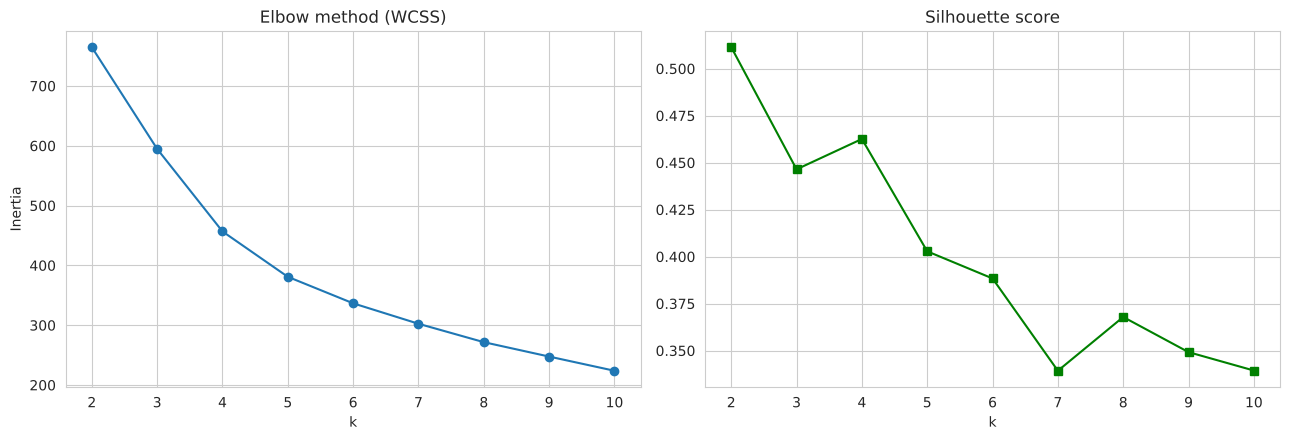

Silhouette scores: {2: np.float64(0.511), 3: np.float64(0.446), 4: np.float64(0.463), 5: np.float64(0.403), 6: np.float64(0.388), 7: np.float64(0.339), 8: np.float64(0.368), 9: np.float64(0.349), 10: np.float64(0.339)}
Best k by silhouette: 2


In [46]:
feat = ['Founded_Year_Clean', 'Date_Added_Year', 'logCIK']
Xs = StandardScaler().fit_transform(Z[feat])

ks = range(2, 11); inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xs)
    inertia.append(km.inertia_); sil.append(silhouette_score(Xs, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(ks, inertia, 'o-'); ax[0].set_title('Elbow method (WCSS)'); ax[0].set_xlabel('k'); ax[0].set_ylabel('Inertia')
ax[1].plot(ks, sil, 's-', color='green'); ax[1].set_title('Silhouette score'); ax[1].set_xlabel('k')
plt.tight_layout(); plt.show()
best_k = list(ks)[int(np.argmax(sil))]
print("Silhouette scores:", dict(zip(ks, np.round(sil, 3))))
print("Best k by silhouette:", best_k)

In [47]:
K = best_k
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Xs)
Z['KMeans_Cluster'] = km.labels_
print(f"K-Means with k={K}: silhouette={silhouette_score(Xs, km.labels_):.3f}, inertia={km.inertia_:.1f}")
print("\nCluster sizes:"); print(Z['KMeans_Cluster'].value_counts().sort_index())
print("\nCluster centres (original units):")
centres = pd.DataFrame(StandardScaler().fit(Z[feat]).inverse_transform(km.cluster_centers_), columns=feat)
centres['CIK (approx)'] = 10**centres['logCIK']; display(centres.round(1))

K-Means with k=2: silhouette=0.511, inertia=764.7

Cluster sizes:
KMeans_Cluster
0    152
1    351
Name: count, dtype: int64

Cluster centres (original units):


,Founded_Year_Clean,Date_Added_Year,logCIK,CIK (approx)
0,1909.1,1980.5,4.8,61364.0
1,1975.9,2009.7,6.0,975580.7


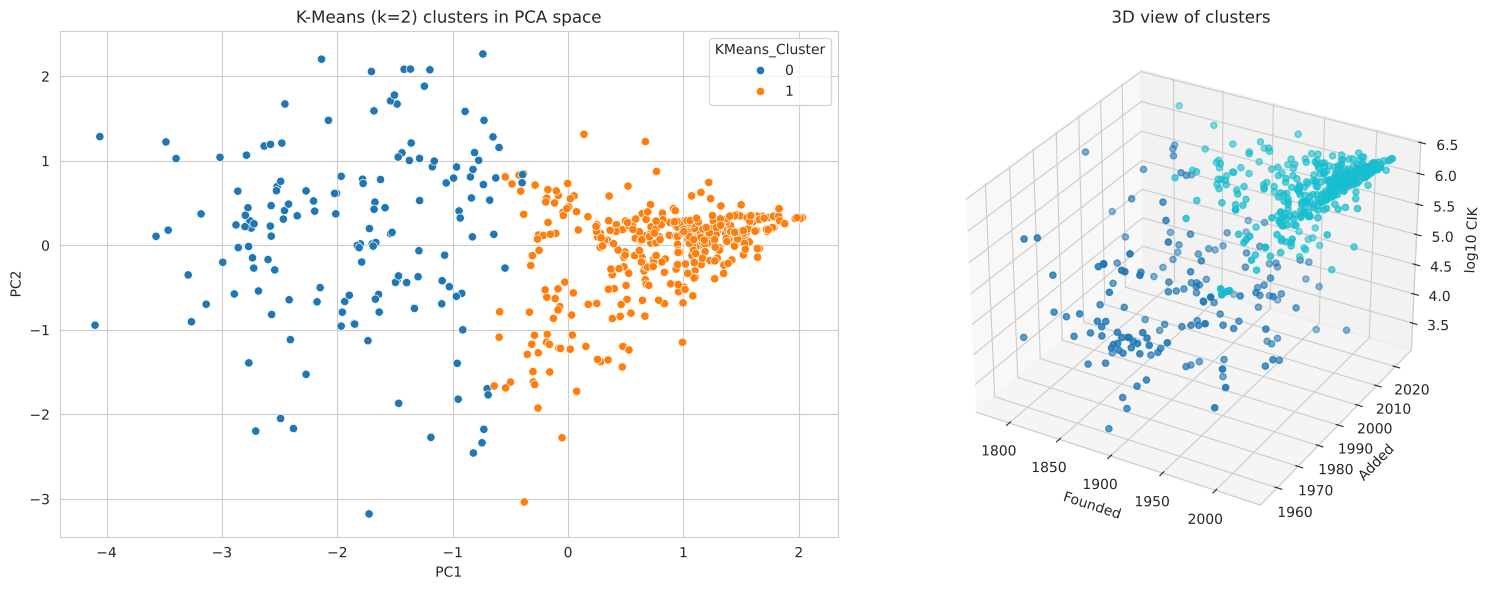

In [48]:
# Visualise clusters: PCA 2D plot + 3D scatter
pcs = PCA(n_components=2).fit_transform(Xs)
fig = plt.figure(figsize=(16, 6))
ax1 = fig.add_subplot(121)
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=Z['KMeans_Cluster'], palette='tab10', ax=ax1)
ax1.set_title(f'K-Means (k={K}) clusters in PCA space'); ax1.set_xlabel('PC1'); ax1.set_ylabel('PC2')
ax2 = fig.add_subplot(122, projection='3d')
sc = ax2.scatter(Z['Founded_Year_Clean'], Z['Date_Added_Year'], Z['logCIK'], c=Z['KMeans_Cluster'], cmap='tab10', s=20)
ax2.set_xlabel('Founded'); ax2.set_ylabel('Added'); ax2.set_zlabel('log10 CIK'); ax2.set_title('3D view of clusters')
plt.tight_layout(); plt.show()

In [49]:
# Profile clusters against the categorical data
prof = df.loc[Z.index, ['Security', 'GICS Sector']].join(Z[['KMeans_Cluster']])
display(pd.crosstab(prof['GICS Sector'], prof['KMeans_Cluster']))
display(Z.groupby('KMeans_Cluster')[['Founded_Year_Clean', 'Date_Added_Year']].agg(['mean', 'min', 'max']).round(1))

KMeans_Cluster,0,1
GICS Sector,,
Communication Services,2,20
Consumer Discretionary,6,46
Consumer Staples,26,12
Energy,9,13
Financials,31,40
Health Care,13,50
Industrials,32,46
Information Technology,10,57
Materials,11,17


Founded_Year_Clean             Date_Added_Year            
                             mean   min   max            mean   min   max
KMeans_Cluster                                                           
0                          1909.1  1784  2005          1980.5  1957  2023
1                          1975.9  1818  2024          2009.7  1957  2024

## 15. Hierarchical Clustering

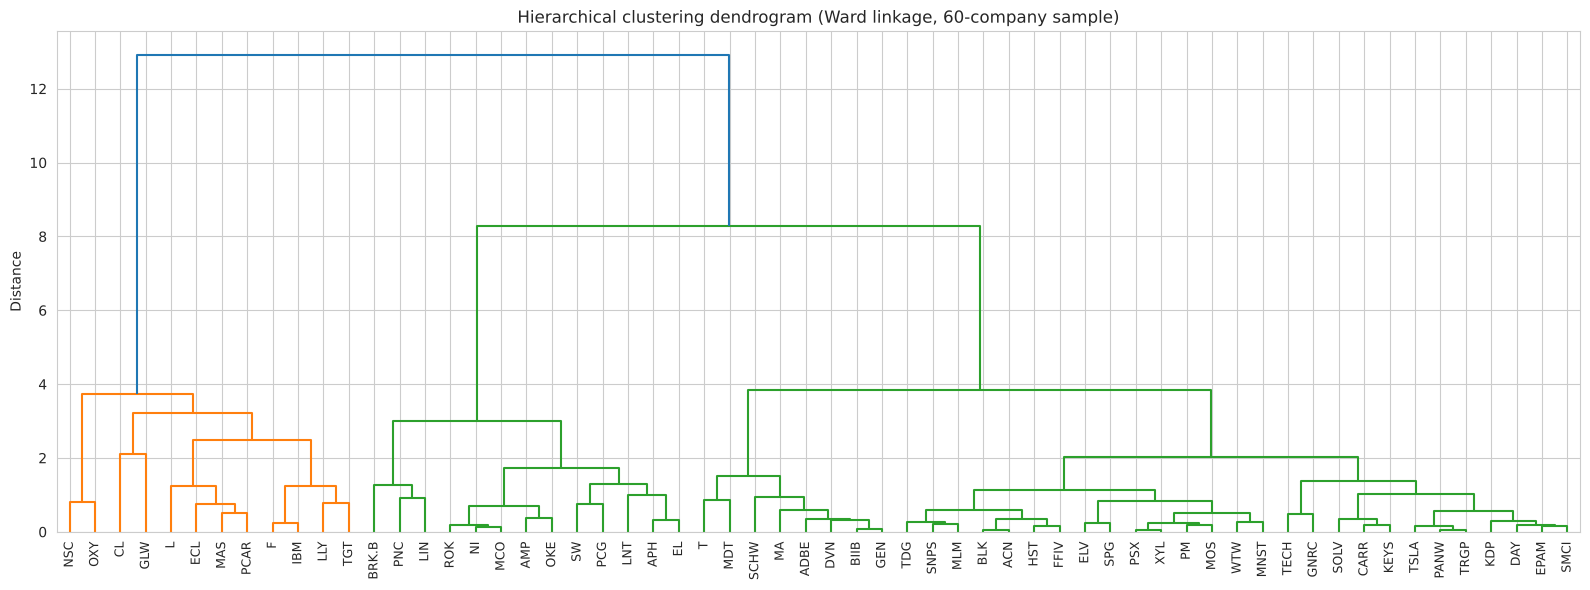

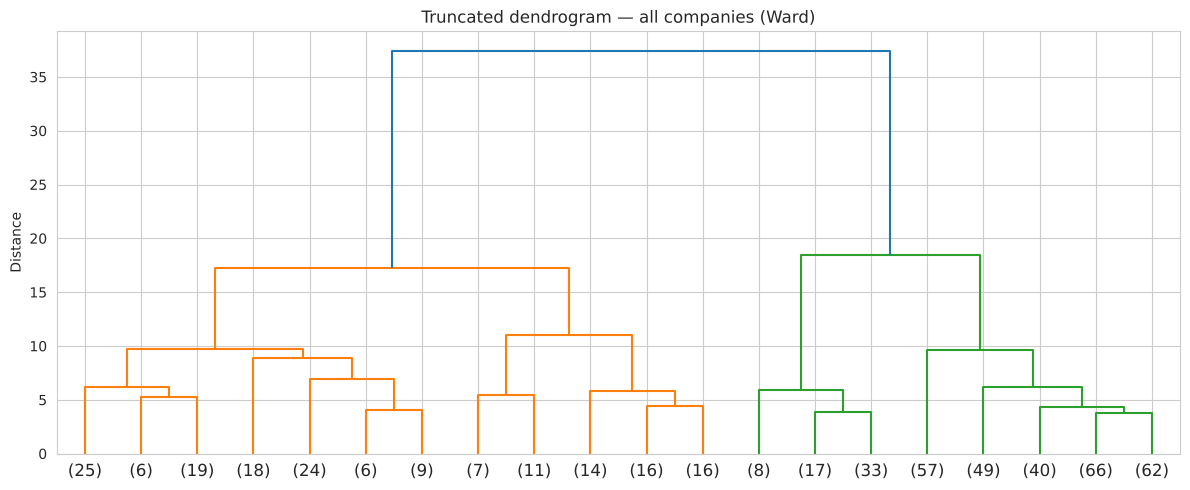

In [50]:
# Dendrogram (Ward linkage) on a random sample of 60 companies for readability, plus full-data linkage
Zl = linkage(Xs, method='ward')
sample_idx = np.random.RandomState(1).choice(len(Z), 60, replace=False)
names = df.loc[Z.index[sample_idx], 'Symbol'].values
plt.figure(figsize=(16, 6))
dendrogram(linkage(Xs[sample_idx], method='ward'), labels=names, leaf_rotation=90, leaf_font_size=9)
plt.title('Hierarchical clustering dendrogram (Ward linkage, 60-company sample)'); plt.ylabel('Distance'); plt.tight_layout(); plt.show()

plt.figure(figsize=(12, 5))
dendrogram(Zl, truncate_mode='lastp', p=20, show_leaf_counts=True)
plt.title('Truncated dendrogram — all companies (Ward)'); plt.ylabel('Distance'); plt.tight_layout(); plt.show()

In [51]:
# Compare linkage methods using cophenetic correlation
from scipy.cluster.hierarchy import cophenet
from scipy.spatial.distance import pdist
d = pdist(Xs)
for m in ['single', 'complete', 'average', 'ward']:
    c, _ = cophenet(linkage(Xs, method=m), d)
    print(f"{m:9s} cophenetic correlation = {c:.3f}")

single    cophenetic correlation = 0.802
complete  cophenetic correlation = 0.734
average   cophenetic correlation = 0.819
ward      cophenetic correlation = 0.752


k=2: silhouette=0.478
k=3: silhouette=0.417
k=4: silhouette=0.433
k=5: silhouette=0.437
k=6: silhouette=0.442
k=7: silhouette=0.336

Chosen k=2. Hierarchical cluster sizes:
Hier_Cluster
0    332
1    171
Name: count, dtype: int64


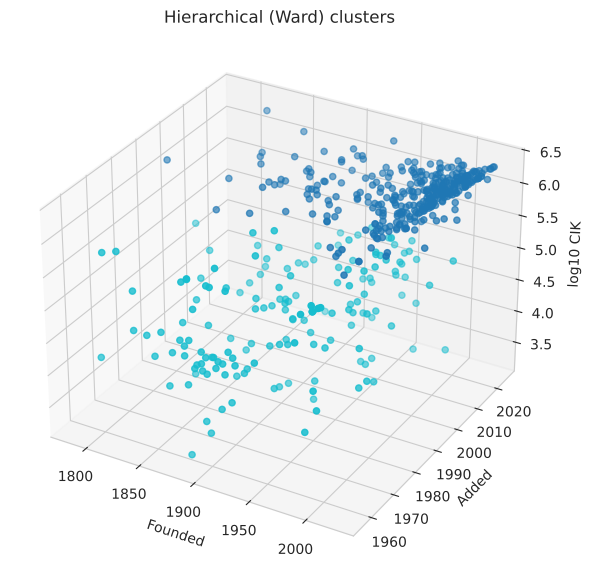

In [52]:
# Cut the tree and evaluate
for k in range(2, 8):
    lab = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(Xs)
    print(f"k={k}: silhouette={silhouette_score(Xs, lab):.3f}")
H_K = K
Z['Hier_Cluster'] = AgglomerativeClustering(n_clusters=H_K, linkage='ward').fit_predict(Xs)
print(f"\nChosen k={H_K}. Hierarchical cluster sizes:"); print(Z['Hier_Cluster'].value_counts().sort_index())

fig = plt.figure(figsize=(9, 7)); ax = fig.add_subplot(111, projection='3d')
ax.scatter(Z['Founded_Year_Clean'], Z['Date_Added_Year'], Z['logCIK'], c=Z['Hier_Cluster'], cmap='tab10', s=20)
ax.set_xlabel('Founded'); ax.set_ylabel('Added'); ax.set_zlabel('log10 CIK'); ax.set_title('Hierarchical (Ward) clusters')
plt.show()

In [53]:
# K-Means vs Hierarchical agreement
from sklearn.metrics import adjusted_rand_score
print("Adjusted Rand Index (K-Means vs Hierarchical):", round(adjusted_rand_score(Z['KMeans_Cluster'], Z['Hier_Cluster']), 3))
display(pd.crosstab(Z['KMeans_Cluster'], Z['Hier_Cluster'], rownames=['KMeans'], colnames=['Hierarchical']))

Adjusted Rand Index (K-Means vs Hierarchical): 0.709


Hierarchical,0,1
KMeans,,
0,10,142
1,322,29


## 16. Phase II Summary
- **1D:** descriptive statistics, skewness/kurtosis, outliers, normality tests and Q-Q plots for each numeric variable; frequency/entropy for sector.
- **2D:** covariance, Pearson/Spearman/Kendall correlation with p-values, regression, ANOVA/Kruskal-Wallis, chi-square with Cramér's V.
- **3D:** 3D scatter/histogram, partial correlation, multiple regression, Mahalanobis outliers, PCA.
- **Clustering:** K-Means (elbow + silhouette) and Hierarchical (Ward dendrogram, cophenetic comparison of linkages), then compared the two with the Adjusted Rand Index.

**Caveat:** the dataset has only three genuinely informative numeric variables, so clusters mostly separate companies by *when they were founded / listed / registered with the SEC*. They describe those timing patterns, not company performance.

**Key findings:**
- None of the three numeric variables is normally distributed (Shapiro-Wilk p < 0.001 for all), so rank-based tests (Spearman, Kruskal-Wallis) are the safer choice.
- Founding year, year added to the index and CIK are all moderately positively correlated (r ≈ 0.48–0.55): younger companies tend to join the index later and have higher CIK numbers.
- Founding year differs significantly across sectors (Kruskal-Wallis p < 0.001), and sector and founding era are associated (Cramér's V ≈ 0.26).
- Both clustering methods split the companies into two groups: an older, longer-listed group (mean founded ≈ 1909, added ≈ 1980) and a younger, more recently listed group (mean founded ≈ 1976, added ≈ 2010). The Adjusted Rand Index between K-Means and Hierarchical is ≈ 0.71, i.e. substantial agreement.

---
# PHASE III — Module 6: PCA and Module 7: Simple Linear Regression (SLR)
Continues in the same notebook, using the cleaned data from Phases I and II.

## 17. Module 6 — Principal Component Analysis (PCA)

In [54]:
feat = ['Founded_Year_Clean', 'Date_Added_Year', 'logCIK']
Xp = StandardScaler().fit_transform(Z[feat])   # standardise: PCA is scale-sensitive

pca_full = PCA().fit(Xp)
evr = pca_full.explained_variance_ratio_
print(pd.DataFrame({'PC': [f'PC{i+1}' for i in range(len(evr))],
                    'eigenvalue': pca_full.explained_variance_.round(3),
                    'explained var %': (evr*100).round(2),
                    'cumulative %': (np.cumsum(evr)*100).round(2)}).to_string(index=False))
print("\nKaiser criterion (eigenvalue > 1) keeps", int((pca_full.explained_variance_ > 1).sum()), "component(s)")

 PC  eigenvalue  explained var %  cumulative %
PC1       1.955            65.05         65.05
PC2       0.565            18.81         83.86
PC3       0.485            16.14        100.00

Kaiser criterion (eigenvalue > 1) keeps 1 component(s)


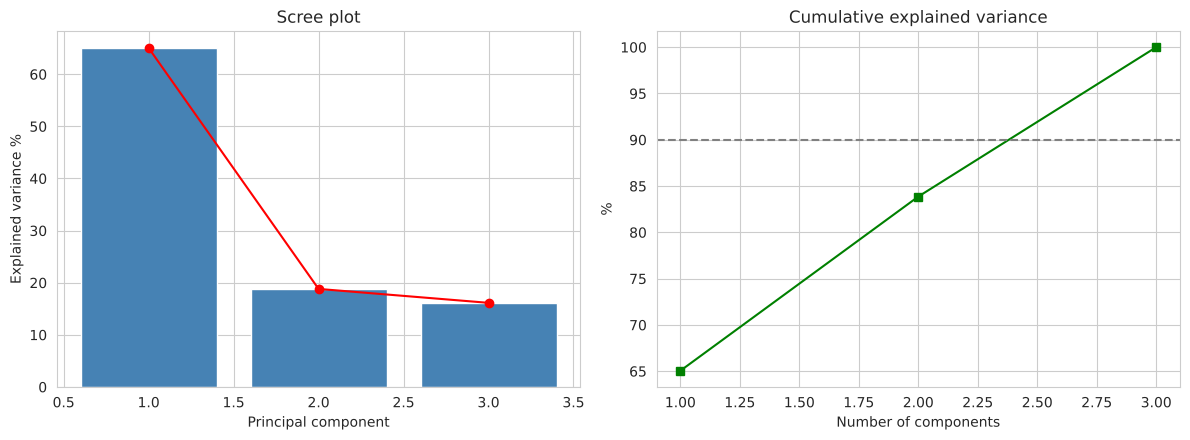

In [55]:
# Scree plot + cumulative variance
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].bar(range(1, len(evr)+1), evr*100, color='steelblue'); ax[0].plot(range(1, len(evr)+1), evr*100, 'ro-')
ax[0].set_title('Scree plot'); ax[0].set_xlabel('Principal component'); ax[0].set_ylabel('Explained variance %')
ax[1].plot(range(1, len(evr)+1), np.cumsum(evr)*100, 's-', color='green'); ax[1].axhline(90, ls='--', color='gray')
ax[1].set_title('Cumulative explained variance'); ax[1].set_xlabel('Number of components'); ax[1].set_ylabel('%')
plt.tight_layout(); plt.show()

,PC1,PC2,PC3
Founded_Year_Clean,0.563,0.798,-0.215
Date_Added_Year,0.591,-0.207,0.780
logCIK,0.578,-0.566,-0.588


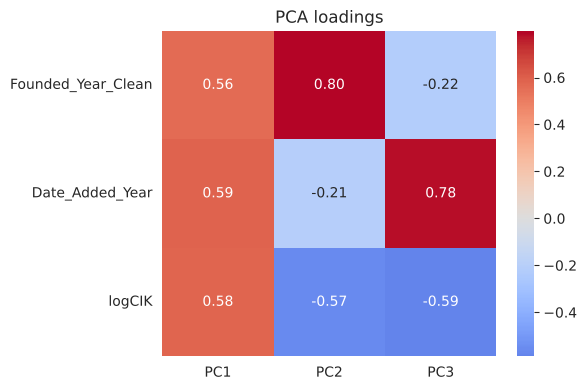

In [56]:
# Loadings (how much each original variable contributes to each PC)
loadings = pd.DataFrame(pca_full.components_.T, index=feat, columns=[f'PC{i+1}' for i in range(len(feat))])
display(loadings.round(3))
plt.figure(figsize=(6, 4)); sns.heatmap(loadings, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('PCA loadings'); plt.tight_layout(); plt.show()

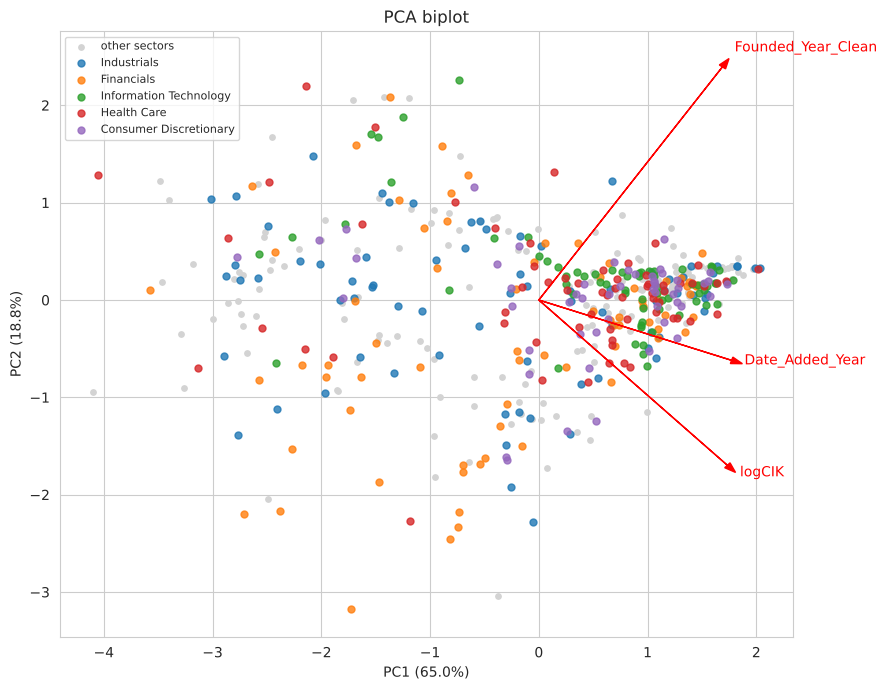

In [57]:
# Project onto first two PCs: scores plot coloured by sector + biplot arrows
scores = pca_full.transform(Xp)[:, :2]
sect = df.loc[Z.index, 'GICS Sector']
top = sect.value_counts().head(5).index
fig, ax = plt.subplots(figsize=(9, 7))
other = ~sect.isin(top)
ax.scatter(scores[other, 0], scores[other, 1], c='lightgray', s=15, label='other sectors')
for s in top:
    m = (sect == s).values; ax.scatter(scores[m, 0], scores[m, 1], s=25, alpha=.8, label=s)
for i, f in enumerate(feat):
    ax.arrow(0, 0, loadings.iloc[i, 0]*3, loadings.iloc[i, 1]*3, color='red', head_width=.07)
    ax.text(loadings.iloc[i, 0]*3.2, loadings.iloc[i, 1]*3.2, f, color='red')
ax.set_xlabel(f'PC1 ({evr[0]*100:.1f}%)'); ax.set_ylabel(f'PC2 ({evr[1]*100:.1f}%)')
ax.set_title('PCA biplot'); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

In [58]:
# Reconstruction check: how much information is lost keeping 2 PCs?
p2 = PCA(n_components=2).fit(Xp)
recon = p2.inverse_transform(p2.transform(Xp))
mse = ((Xp - recon)**2).mean()
print(f"Variance kept with 2 PCs: {p2.explained_variance_ratio_.sum()*100:.1f}%  |  reconstruction MSE (standardised units): {mse:.3f}")
Z['PC1'], Z['PC2'] = scores[:, 0], scores[:, 1]
# Re-run K-Means in PCA space to see if clusters survive dimensionality reduction
km_pc = KMeans(n_clusters=2, n_init=10, random_state=42).fit(scores)
print("Adjusted Rand Index, K-Means on 3 vars vs on 2 PCs:", round(adjusted_rand_score(Z['KMeans_Cluster'], km_pc.labels_), 3))

Variance kept with 2 PCs: 83.9%  |  reconstruction MSE (standardised units): 0.161
Adjusted Rand Index, K-Means on 3 vars vs on 2 PCs: 0.936


## 18. Module 7 — Simple Linear Regression (SLR)
**Question:** can the year a company was **founded** predict the year it was **added to the S&P 500**?

Model: `Date_Added_Year = β0 + β1 · Founded_Year_Clean + ε`

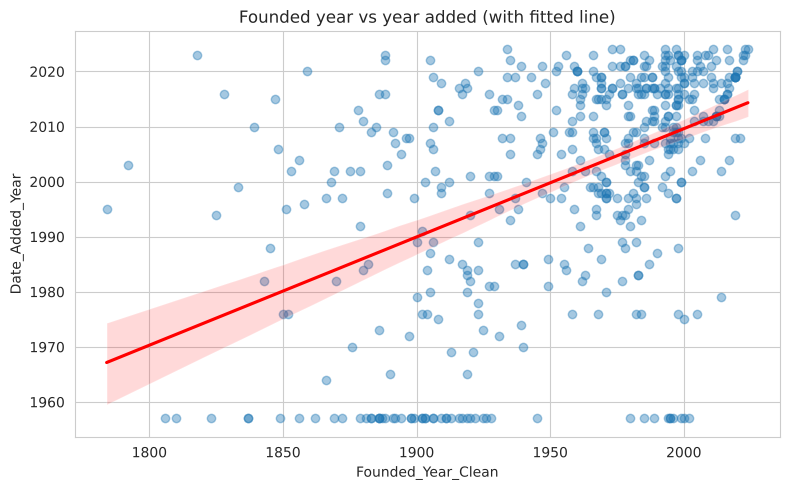

Pearson r = 0.475


In [59]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

X = Z[['Founded_Year_Clean']].values; y = Z['Date_Added_Year'].values
plt.figure(figsize=(8, 5)); sns.regplot(x=Z['Founded_Year_Clean'], y=Z['Date_Added_Year'],
            scatter_kws={'alpha': .4}, line_kws={'color': 'red'})
plt.title('Founded year vs year added (with fitted line)'); plt.tight_layout(); plt.show()
print("Pearson r =", round(np.corrcoef(Z['Founded_Year_Clean'], y)[0, 1], 3))

In [60]:
# Fit on the full data for inference (coefficients, standard errors, CI, p-values)
res = stats.linregress(Z['Founded_Year_Clean'], y)
n = len(y); t = stats.t.ppf(0.975, n-2)
print(f"Intercept (b0) = {res.intercept:.3f}")
print(f"Slope     (b1) = {res.slope:.4f}  (SE={res.stderr:.4f}, 95% CI [{res.slope - t*res.stderr:.4f}, {res.slope + t*res.stderr:.4f}])")
print(f"R^2 = {res.rvalue**2:.4f},  t-test on slope: p = {res.pvalue:.3g}")
print(f"Interpretation: every 10 years later a company was founded, it joined the index on average {res.slope*10:.2f} years later.")

Intercept (b0) = 1616.540
Slope     (b1) = 0.1965  (SE=0.0163, 95% CI [0.1646, 0.2285])
R^2 = 0.2254,  t-test on slope: p = 1.21e-29
Interpretation: every 10 years later a company was founded, it joined the index on average 1.97 years later.


Train: R^2=0.214  RMSE=17.91  MAE=14.12
Test : R^2=0.262  RMSE=17.09  MAE=13.17
Baseline (always predict the mean) test RMSE = 20.02


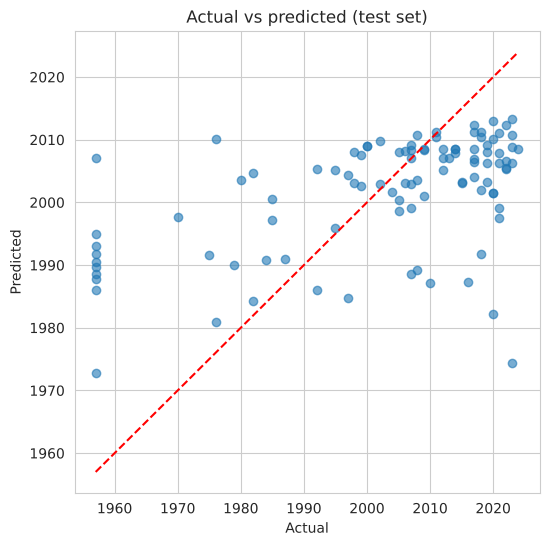

In [61]:
# Train/test evaluation (80/20 split)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)
lr = LinearRegression().fit(Xtr, ytr)
pred_tr, pred_te = lr.predict(Xtr), lr.predict(Xte)
print(f"Train: R^2={r2_score(ytr, pred_tr):.3f}  RMSE={np.sqrt(mean_squared_error(ytr, pred_tr)):.2f}  MAE={mean_absolute_error(ytr, pred_tr):.2f}")
print(f"Test : R^2={r2_score(yte, pred_te):.3f}  RMSE={np.sqrt(mean_squared_error(yte, pred_te)):.2f}  MAE={mean_absolute_error(yte, pred_te):.2f}")
base = np.sqrt(mean_squared_error(yte, np.full_like(yte, ytr.mean(), dtype=float)))
print(f"Baseline (always predict the mean) test RMSE = {base:.2f}")
plt.figure(figsize=(6, 6)); plt.scatter(yte, pred_te, alpha=.6); lim = [yte.min(), yte.max()]
plt.plot(lim, lim, 'r--'); plt.xlabel('Actual'); plt.ylabel('Predicted'); plt.title('Actual vs predicted (test set)'); plt.show()

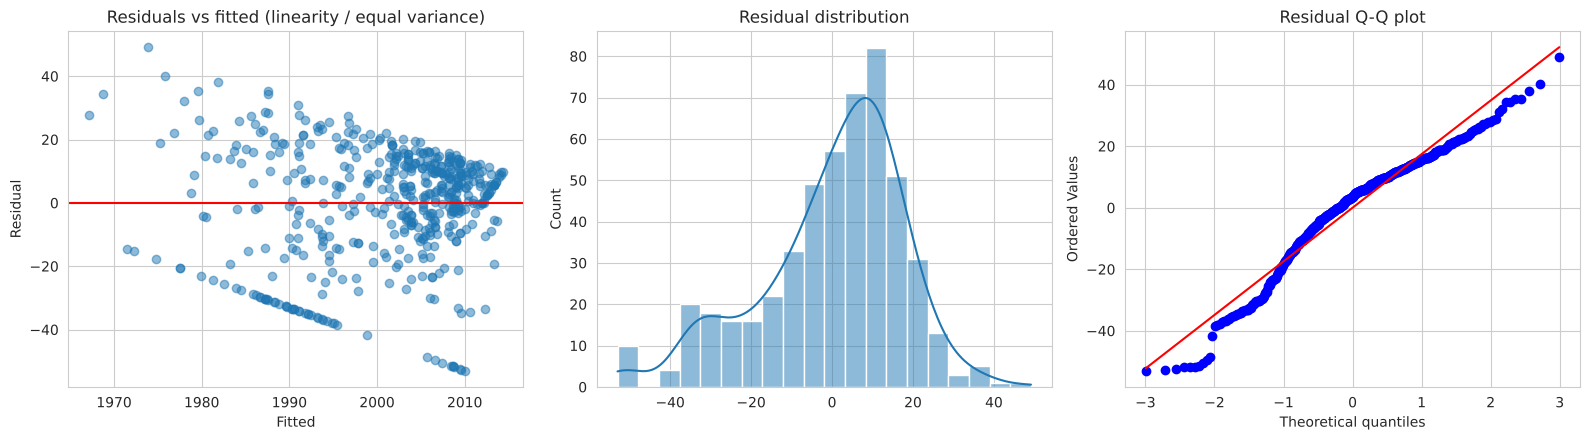

Shapiro-Wilk on residuals: p = 2.99e-11
Heteroscedasticity check (resid^2 vs x): p = 9.03e-12 -> variance NOT constant
Durbin-Watson: 2.072 (~2 means no autocorrelation; rows are alphabetical so it is not meaningful here)


In [62]:
# Assumption checks on residuals
resid_ = y - (res.intercept + res.slope * Z['Founded_Year_Clean'].values)
fitted = res.intercept + res.slope * Z['Founded_Year_Clean'].values
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].scatter(fitted, resid_, alpha=.5); ax[0].axhline(0, color='red'); ax[0].set_title('Residuals vs fitted (linearity / equal variance)')
ax[0].set_xlabel('Fitted'); ax[0].set_ylabel('Residual')
sns.histplot(resid_, kde=True, ax=ax[1]); ax[1].set_title('Residual distribution')
stats.probplot(resid_, plot=ax[2]); ax[2].set_title('Residual Q-Q plot')
plt.tight_layout(); plt.show()
print("Shapiro-Wilk on residuals: p =", f"{stats.shapiro(resid_).pvalue:.3g}")
# Breusch-Pagan style check: regress squared residuals on x
bp = stats.linregress(Z['Founded_Year_Clean'], resid_**2)
print("Heteroscedasticity check (resid^2 vs x): p =", f"{bp.pvalue:.3g}", "->", "variance NOT constant" if bp.pvalue < .05 else "variance looks constant")
dw = np.sum(np.diff(resid_)**2) / np.sum(resid_**2)
print("Durbin-Watson:", round(dw, 3), "(~2 means no autocorrelation; rows are alphabetical so it is not meaningful here)")

In [63]:
# Influential points (Cook's distance) and prediction example
xm = Z['Founded_Year_Clean'].values; h = 1/n + (xm - xm.mean())**2 / ((xm - xm.mean())**2).sum()
mse_ = (resid_**2).sum()/(n-2); cooks = resid_**2/(2*mse_) * h/(1-h)**2
print("Points with Cook's D > 4/n:", int((cooks > 4/n).sum()))
print(df.loc[Z.index[np.argsort(cooks)[-5:]], ['Security', 'Founded_Year_Clean', 'Date_Added_Year']].assign(CooksD=np.sort(cooks)[-5:].round(3)))
for yr in [1900, 1950, 2000]:
    print(f"A company founded in {yr} -> predicted year added to S&P 500: {res.intercept + res.slope*yr:.0f}")

Points with Cook's D > 4/n: 50
                     Security  Founded_Year_Clean  Date_Added_Year  CooksD
107           Church & Dwight                1847             2015   0.024
58                 BNY Mellon                1784             1995   0.035
113  Citizens Financial Group                1828             2016   0.041
426  State Street Corporation                1792             2003   0.048
79               Bunge Global                1818             2023   0.071
A company founded in 1900 -> predicted year added to S&P 500: 1990
A company founded in 1950 -> predicted year added to S&P 500: 2000
A company founded in 2000 -> predicted year added to S&P 500: 2010


## 19. Phase III Summary
- **PCA:** the first principal component captures the shared "older vs younger company" signal across founding year, year added and CIK; the loadings and biplot show all three variables push the same way. Two components retain most of the variance, and K-Means on the 2 PCs gives nearly the same clusters as on the original variables.
- **SLR:** founding year is a statistically significant but **weak** predictor of the year a company joined the index (R² ≈ 0.22). Slope ≈ 0.2: companies founded 10 years later joined about 2 years later. Predictions on the test set only modestly beat the "predict the mean" baseline, and the residual checks show the normality and constant-variance assumptions are not perfectly met, so the model is illustrative rather than reliable for prediction.